# 11 · All trained models compared: training and evaluation
**Project:** Noise-Robust Speech Recognition with Word-Level Error Detection (Group 9) · Milestone 4

Each model has its own notebook with the full details (`M4_05_model_A_clean` … `M4_10_model_B960_rev_s2`).
This notebook puts **every model we trained** side by side, on the same axes, and adds the hyperparameter sweep:

| Model | Starts from | Labelled training data | Augmentation | Steps | Peak lr | Why we trained it |
|---|---|---|---|---:|---:|---|
| `A_clean` | wav2vec2-base | train-clean-100 (100 h) | none | 36k | 5e-5 | baseline: clean training only |
| `B_noisy` | wav2vec2-base | train-clean-100 (100 h) | noise, SNR 0–20 dB | 36k | 5e-5 | O2: same recipe + noise |
| `B2_lr1e-4` | wav2vec2-base | train-clean-100 (100 h) | as B | 36k | **1e-4** | full-length check of the sweep winner |
| `B460` | wav2vec2-base | train-clean-100 + 360 (**464 h**) | as B | 80k | 1e-4 | more labelled data |
| `B960_rev` | **B460 best** | all **960 h** (adds train-other-500) | as B + reverb, speed 0.9/1.1, telephone band | 40k | 5e-5 | more data + new distortions; **best single model** |
| `B960_rev_s2` | B460 best | all 960 h | as B960_rev, **seed 7** | 40k | 5e-5 | second seed, for ROVER |
| `hp_*` (7 runs) | wav2vec2-base | train-clean-100 | as B | 8k | various | hyperparameter sweep |

The reference model `facebook/wav2vec2-base-960h` (not trained by us) and the final **ROVER** combination of
B960_rev_s2 + B960_rev + B460 are included in the evaluation part.

**Everything here is read from small files that are in the repository** (`configs/`, `experiments/runs/*/train_log.csv`,
`eval_log.csv`, `config.json`, `experiments/results/*/summary.csv`, `metrics.json`), so the notebook runs on a fresh
clone without the data, the weights or a GPU. Code that produced them: `scripts/train.py`, `scripts/evaluate.py`,
`scripts/decode_lm.py`, `scripts/rover.py`. The trained models are on Hugging Face (links in the M4 report, Section 6).

**Contents**
1. Setup
2. Configurations side by side
3. Training curves of all main models
4. Model by model
5. Hyperparameter sweep (7 short runs)
6. Training stability and cost
7. Test results: greedy decoding
8. Test results: 4-gram LM and the final ROVER system
9. Harder held-out conditions (reverb, −5 dB)
10. Comparison with the published wav2vec 2.0 results
11. Summary

## 1 · Setup

In [1]:
import sys, json, warnings
from pathlib import Path
cwd = Path.cwd()
REPO = next(p for p in (cwd, *cwd.parents) if (p / "src" / "group9_ds_ai_lab").is_dir())
sys.path.insert(0, str(REPO / "src"))
from group9_ds_ai_lab.utils.paths import *   # noqa  (RUNS, EVAL, CONFIGS, ...)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
from IPython.display import display, Markdown
from group9_ds_ai_lab.utils.plotstyle import apply_style, SERIES, INK, INK2, GRID, SURF
apply_style(); plt.rcParams["axes.axisbelow"] = True; warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 60)

# fixed colour per model (colour follows the model in every figure)
MAIN = ["A_clean", "B_noisy", "B2_lr1e-4", "B460", "B960_rev", "B960_rev_s2"]
COLOR = {"ref_base960h": "#9a9893", "A_clean": SERIES[0], "B_noisy": SERIES[1], "B2_lr1e-4": SERIES[3],
         "B460": SERIES[2], "B960_rev": SERIES[6], "B960_rev_s2": SERIES[4], "rover3_final": SERIES[7]}
LABEL = {"ref_base960h": "reference base-960h (not ours)", "A_clean": "A (clean, 100 h)", "B_noisy": "B (noise, 100 h)",
         "B2_lr1e-4": "B2 (noise, 100 h, lr 1e-4)", "B460": "B460 (noise, 464 h)",
         "B960_rev": "B960_rev (960 h + reverb)", "B960_rev_s2": "B960_rev_s2 (seed 7)",
         "rover3_final": "ROVER final (3 models)"}
# reference words per test split, used to pool test-clean + test-other exactly as the evaluation scripts do
N_WORDS = {"test.clean": 52576, "test.other": 52343}
print("repo:", REPO)

repo: /home/user1/DSAI/Group-9-DS-and-AI-Lab-Project


## 2 · Configurations side by side
`config.json` is the exact configuration saved by `scripts/train.py` at the start of each run (the YAML file merged
with the defaults). Only the keys that differ between at least two runs are shown; the shared settings follow.

In [2]:
cfg = {n: json.load(open(RUNS / n / "config.json")) for n in MAIN}
C = pd.DataFrame(cfg).T
C["train_manifest"] = C["train_manifest"].fillna("train_clean_100 (default)")
C["init_from"] = C["init_from"].fillna("facebook/wav2vec2-base")
show = lambda v: str(v) if not isinstance(v, float) or not np.isnan(v) else "-"
C = C.map(show)
diff = [k for k in C.columns if C[k].nunique() > 1 and k != "name"]
display(Markdown("**Settings that differ between runs**")); display(C[diff])
same = [k for k in C.columns if C[k].nunique() == 1 and k not in ("name",)]
display(Markdown("**Settings shared by all six runs**")); display(C[same].iloc[[0]].T.rename(columns={C.index[0]: "value"}))

**Settings that differ between runs**

,augment,max_steps,lr,warmup_ratio,eval_every,save_every,seed,train_manifest,init_from,p_speed,speeds,p_reverb,p_bandlimit
A_clean,False,36000,5e-05,0.08,2000,2000,42,train_clean_100 (default),facebook/wav2vec2-base,-,-,-,-
B_noisy,True,36000,5e-05,0.08,2000,2000,42,train_clean_100 (default),facebook/wav2vec2-base,-,-,-,-
B2_lr1e-4,True,36000,0.0001,0.08,2000,2000,42,train_clean_100 (default),facebook/wav2vec2-base,-,-,-,-
B460,True,80000,0.0001,0.05,4000,4000,42,train_460.csv,facebook/wav2vec2-base,0.0,"[0.9, 1.1]",0.0,0.0
B960_rev,True,40000,5e-05,0.05,2000,4000,42,train_960.csv,experiments/runs/B460/best,0.3,"[0.9, 1.1]",0.3,0.1
B960_rev_s2,True,40000,5e-05,0.05,2000,4000,7,train_960.csv,experiments/runs/B460/best,0.3,"[0.9, 1.1]",0.3,0.1


**Settings shared by all six runs**

,value
init_model,facebook/wav2vec2-base
p_clean,0.2
snr_min,0.0
snr_max,20.0
weight_decay,0.005
max_grad_norm,1.0
max_batch_seconds,640
grad_accum,1
log_every,50
num_workers,28


## 3 · Training curves of all main models
`train_log.csv` has one row every 50 optimizer steps (CTC loss, learning rate, gradient norm, speed, GPU memory).
`eval_log.csv` has one row per validation: WER on 2,000 clean dev utterances and on 2,000 noisy dev utterances
(held-out MUSAN noise files). Checkpoint selection uses the **mean of the two** (`wer_avg`).

The x-axis on the right is **hours of audio processed** (steps × 640 s), which makes runs with different numbers
of steps comparable. B960_rev and B960_rev_s2 continue from B460, so their curves are drawn starting where B460 ended.

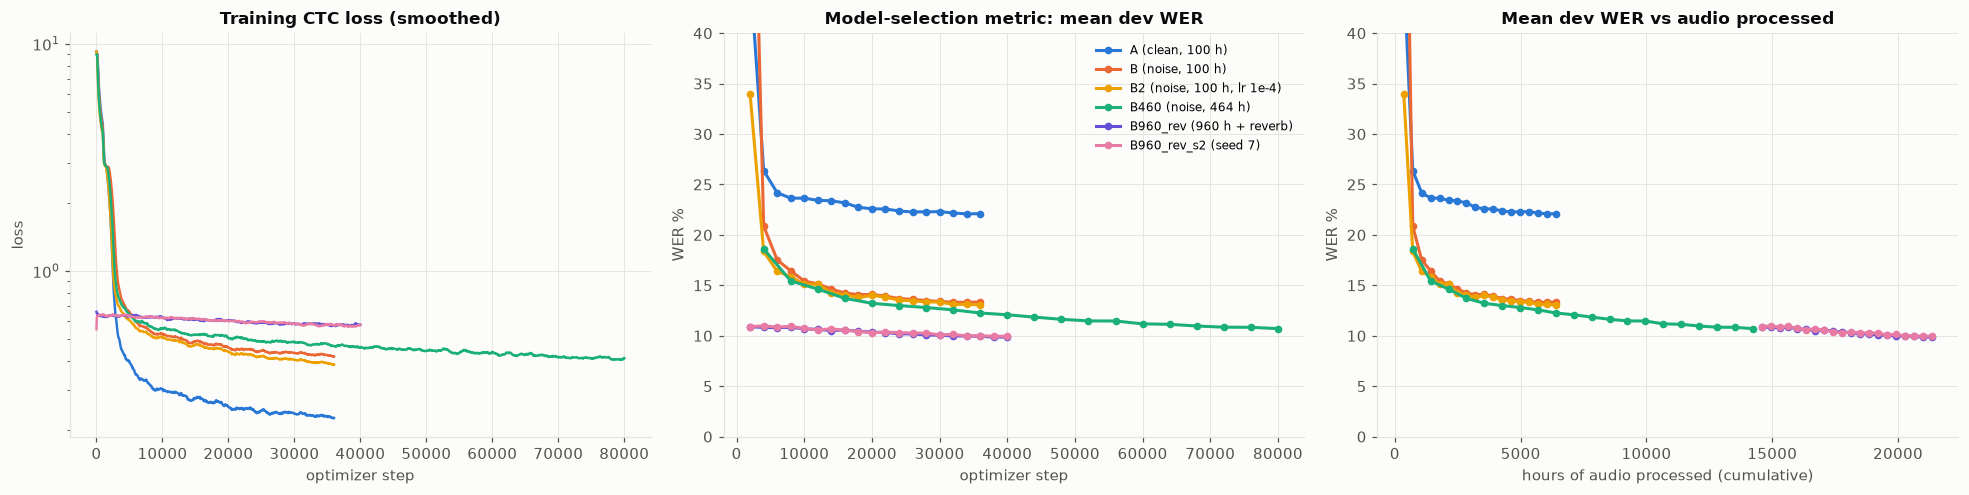

In [3]:
tl = {n: pd.read_csv(RUNS / n / "train_log.csv") for n in MAIN}
el = {n: pd.read_csv(RUNS / n / "eval_log.csv") for n in MAIN}
H = 640 / 3600  # hours of (padded) audio per step
offset = {n: (tl["B460"].step.max() * H if cfg[n].get("init_from") else 0) for n in MAIN}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for n in MAIN:
    t, e = tl[n], el[n]
    axes[0].plot(t.step, t.loss.rolling(20, min_periods=1).mean(), color=COLOR[n], label=LABEL[n], lw=1.6)
    axes[1].plot(e.step, e.wer_avg * 100, color=COLOR[n], marker="o", ms=4, label=LABEL[n])
    axes[2].plot(offset[n] + e.step * H, e.wer_avg * 100, color=COLOR[n], marker="o", ms=4, label=LABEL[n])
axes[0].set(title="Training CTC loss (smoothed)", xlabel="optimizer step", ylabel="loss", yscale="log")
axes[1].set(title="Model-selection metric: mean dev WER", xlabel="optimizer step", ylabel="WER %", ylim=(0, 40))
axes[2].set(title="Mean dev WER vs audio processed", xlabel="hours of audio processed (cumulative)", ylabel="WER %", ylim=(0, 40))
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

- **Loss levels are not comparable between models**: A trains on clean audio, B-type models on noisy audio, and
  B960_rev also on reverberant, sped-up and band-limited audio. A higher training loss for those is expected.
- On the dev WER, each step up in data moves the whole curve down: B → B460 → B960_rev.
- B960_rev starts at B460's level (it continues from B460's weights) and keeps improving for 40k more steps.

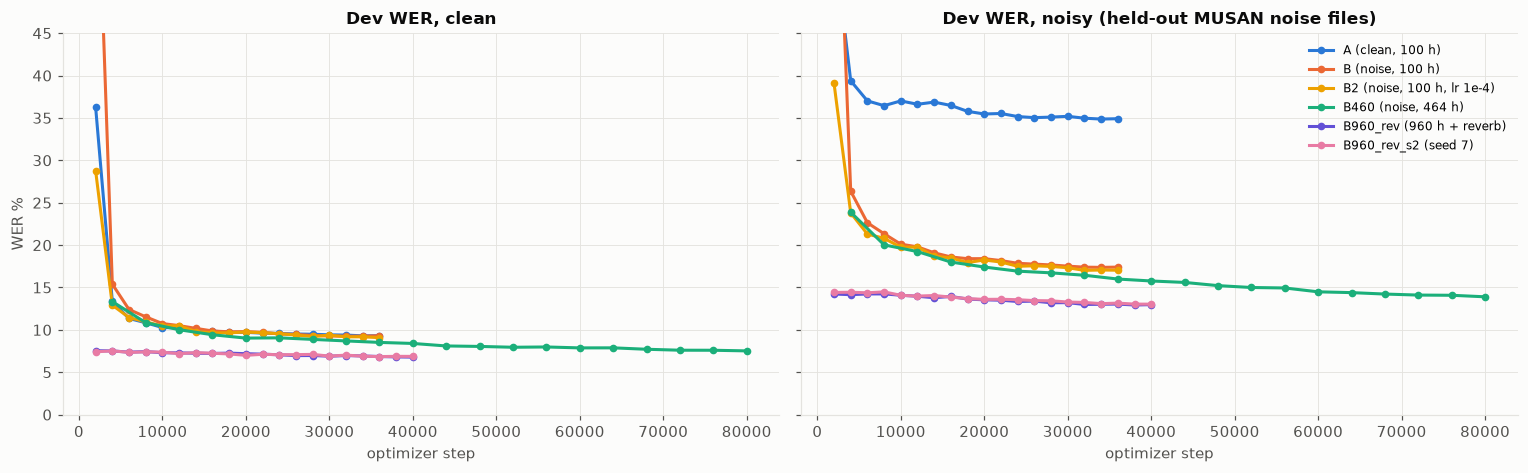

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for n in MAIN:
    e = el[n]
    axes[0].plot(e.step, e.wer_clean * 100, color=COLOR[n], marker="o", ms=4, label=LABEL[n])
    axes[1].plot(e.step, e.wer_noisy * 100, color=COLOR[n], marker="o", ms=4, label=LABEL[n])
axes[0].set(title="Dev WER, clean", xlabel="optimizer step", ylabel="WER %", ylim=(0, 45))
axes[1].set(title="Dev WER, noisy (held-out MUSAN noise files)", xlabel="optimizer step", ylim=(0, 45))
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

The clearest single picture of **O2**: on clean dev speech A and B are almost the same, but on noisy dev speech A
stays at about 35 % while every noise-trained model keeps improving.

## 4 · Model by model
For each model: its learning-rate schedule, its dev WER curves, and the best checkpoint (the one saved in `best/`
and published on Hugging Face).

In [5]:
def best_row(n):
    e = el[n]; b = e.loc[e.wer_avg.idxmin()]
    t = tl[n]
    hours = (t.sec_per_step.iloc[1:] * t.step.diff().iloc[1:]).sum() / 3600
    return {"model": n, "best step": int(b.step), "of steps": int(t.step.max()), "epochs": int(t.epoch.max()),
            "dev WER clean %": round(b.wer_clean * 100, 2), "dev WER noisy %": round(b.wer_noisy * 100, 2),
            "dev WER mean %": round(b.wer_avg * 100, 2), "dev CER clean %": round(b.cer_clean * 100, 2),
            "final train loss": round(t.loss.tail(20).mean(), 3), "GPU hours": round(hours, 2)}

def show_run(n, note=""):
    t, e = tl[n], el[n]
    fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
    axes[0].plot(t.step, t.lr, color=COLOR[n]); axes[0].set(title=f"{n}: learning rate", xlabel="step", ylabel="lr")
    axes[1].plot(t.step, t.loss.rolling(20, min_periods=1).mean(), color=COLOR[n])
    axes[1].set(title=f"{n}: training loss", xlabel="step", yscale="log")
    axes[2].plot(e.step, e.wer_clean * 100, color=COLOR[n], marker="o", ms=4, label="clean dev")
    axes[2].plot(e.step, e.wer_noisy * 100, color=COLOR[n], marker="o", ms=4, ls="--", label="noisy dev")
    b = e.loc[e.wer_avg.idxmin()]
    axes[2].axvline(b.step, color=GRID, lw=1.2)
    axes[2].annotate(f"best step {int(b.step):,}", (b.step, 0.97), xycoords=("data", "axes fraction"), ha="right", va="top", fontsize=8, color=INK2)
    axes[2].set(title=f"{n}: dev WER", xlabel="step", ylabel="WER %", ylim=(0, min(45, e.wer_noisy.iloc[1:].max() * 100 * 1.25)))
    axes[2].legend(fontsize=8)
    plt.tight_layout(); plt.show()
    display(pd.DataFrame([best_row(n)]).set_index("model"))
    print("example at best step:\n  REF", b.example_ref, "\n  HYP", b.example_hyp)

### 4.1 Model A: clean training (100 h)
wav2vec2-base + a new 32-character CTC head, fine-tuned on clean train-clean-100 only. The noisy dev WER flattens at about 35 % after 6k steps: more clean training does not make it robust.

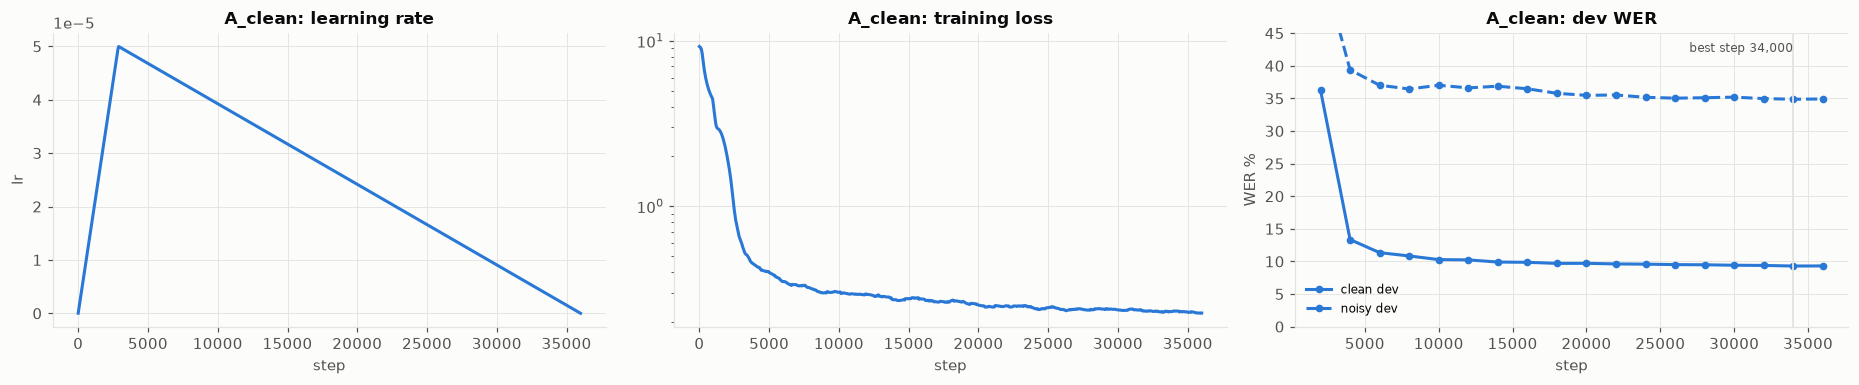

,best step,of steps,epochs,dev WER clean %,dev WER noisy %,dev WER mean %,dev CER clean %,final train loss,GPU hours
model,,,,,,,,,
A_clean,34000,36000,59,9.29,34.87,22.08,3.25,0.226,3.82


example at best step:
  REF HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED 
  HYP HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKEY THE BOYS ROARED


In [6]:
show_run("A_clean")

### 4.2 Model B: noise-augmented (100 h)
Identical to A except that 80 % of training utterances get noise mixed in at 0–20 dB SNR (white, pink and MUSAN training files). Same clean dev WER as A, half the noisy dev WER.

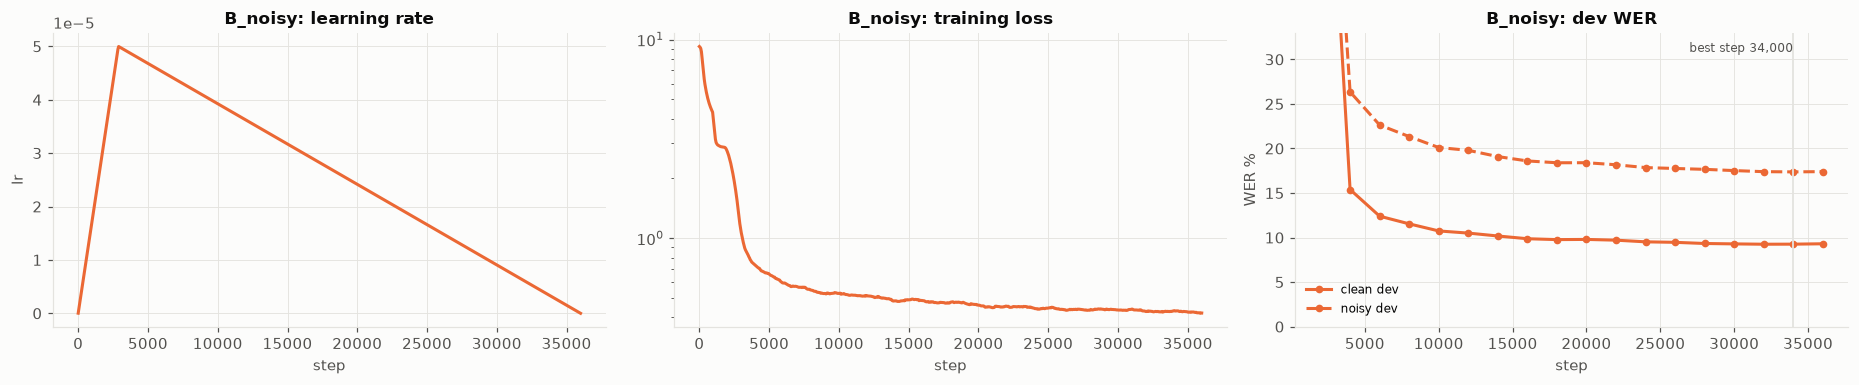

,best step,of steps,epochs,dev WER clean %,dev WER noisy %,dev WER mean %,dev CER clean %,final train loss,GPU hours
model,,,,,,,,,
B_noisy,34000,36000,59,9.26,17.37,13.32,3.23,0.421,3.83


example at best step:
  REF HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED 
  HYP HAT TOO CLOSE TO BE I COULDN'T GET IT EXPLAINED CUNKEY THE BOY'S RARED


In [7]:
show_run("B_noisy")

### 4.3 Model B2: B with learning rate 1e-4
The sweep (Section 5) found lr 1e-4 best at 8k steps. B2 checks whether that holds at the full 36k steps: the gain shrinks to about 0.3 points, so the sweep mostly measured speed of learning. lr 1e-4 was kept for B460.

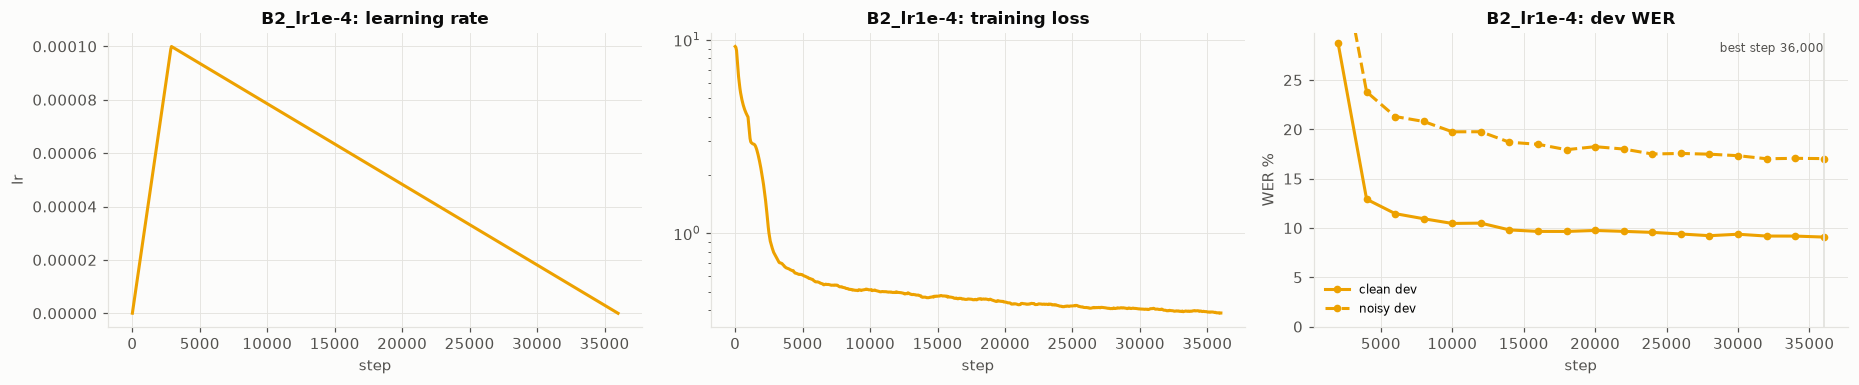

,best step,of steps,epochs,dev WER clean %,dev WER noisy %,dev WER mean %,dev CER clean %,final train loss,GPU hours
model,,,,,,,,,
B2_lr1e-4,36000,36000,59,9.08,17.03,13.06,3.23,0.387,3.95


example at best step:
  REF HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED 
  HYP HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKEY THE BOYS ROARED


In [8]:
show_run("B2_lr1e-4")

### 4.4 Model B460: 464 h of labelled data
Fresh fine-tune of wav2vec2-base on train-clean-100 + train-clean-360 with B's noise recipe and lr 1e-4, 80k steps (about 8 GPU-hours). More labelled data gave the largest single improvement.

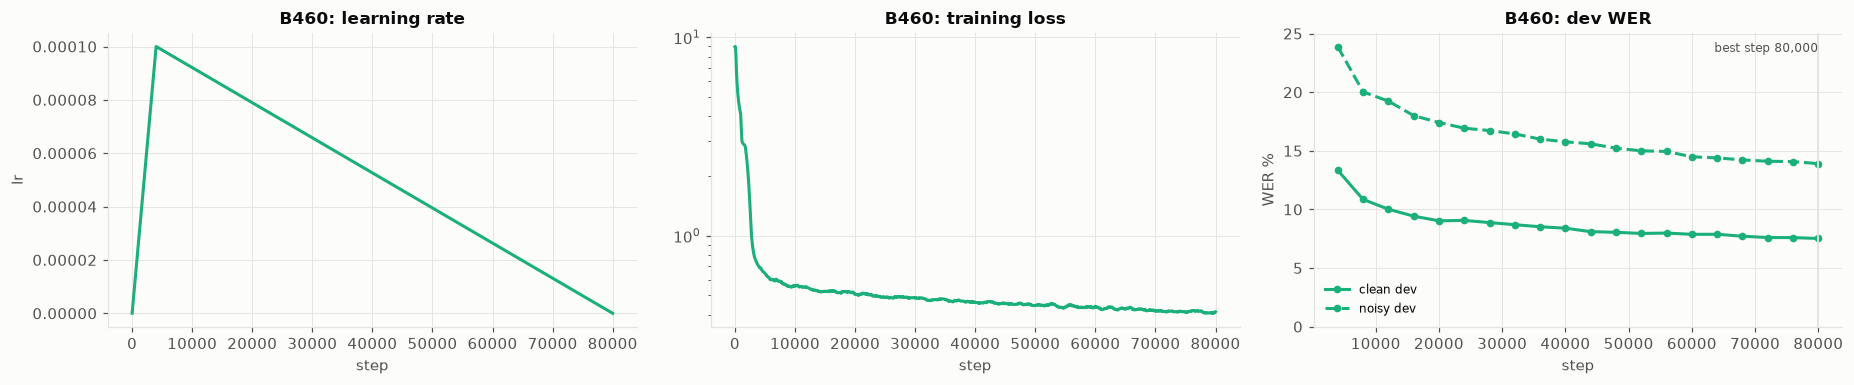

,best step,of steps,epochs,dev WER clean %,dev WER noisy %,dev WER mean %,dev CER clean %,final train loss,GPU hours
model,,,,,,,,,
B460,80000,80000,28,7.52,13.9,10.71,2.61,0.414,8.41


example at best step:
  REF HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED 
  HYP HAT TOO CLOSE TO BE I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED


In [9]:
show_run("B460")

### 4.5 Model B960_rev: 960 h + reverberation, speed and telephone augmentation (best single model)
Continues from B460's best checkpoint on all 960 h (adds the harder train-other-500 speakers). New distortions: simulated-room reverberation (p 0.3), speed 0.9×/1.1× (p 0.3), telephone band-limit (p 0.1). Lower peak lr 5e-5 and 5 % warm-up, because it starts from an already trained recogniser. Its first evaluation is already at B460's level: there is no forgetting.

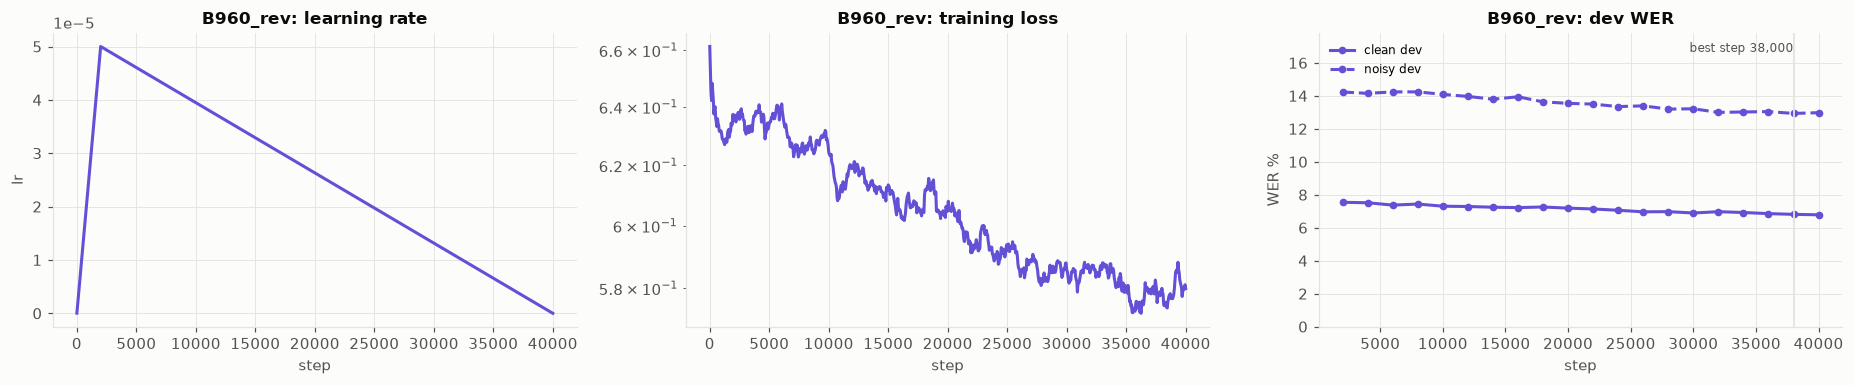

,best step,of steps,epochs,dev WER clean %,dev WER noisy %,dev WER mean %,dev CER clean %,final train loss,GPU hours
model,,,,,,,,,
B960_rev,38000,40000,6,6.81,12.93,9.87,2.27,0.58,3.83


example at best step:
  REF HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED 
  HYP HAT TOO CLOSE TO BE I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED


In [10]:
show_run("B960_rev")

### 4.6 Model B960_rev_s2: second seed
Identical to B960_rev except the seed (7 instead of 42): different data order, noise draws and augmentation choices. It lands within 0.1 points of B960_rev, which also shows how much of a difference between two runs is just seed noise. Used as the pivot of the ROVER combination.

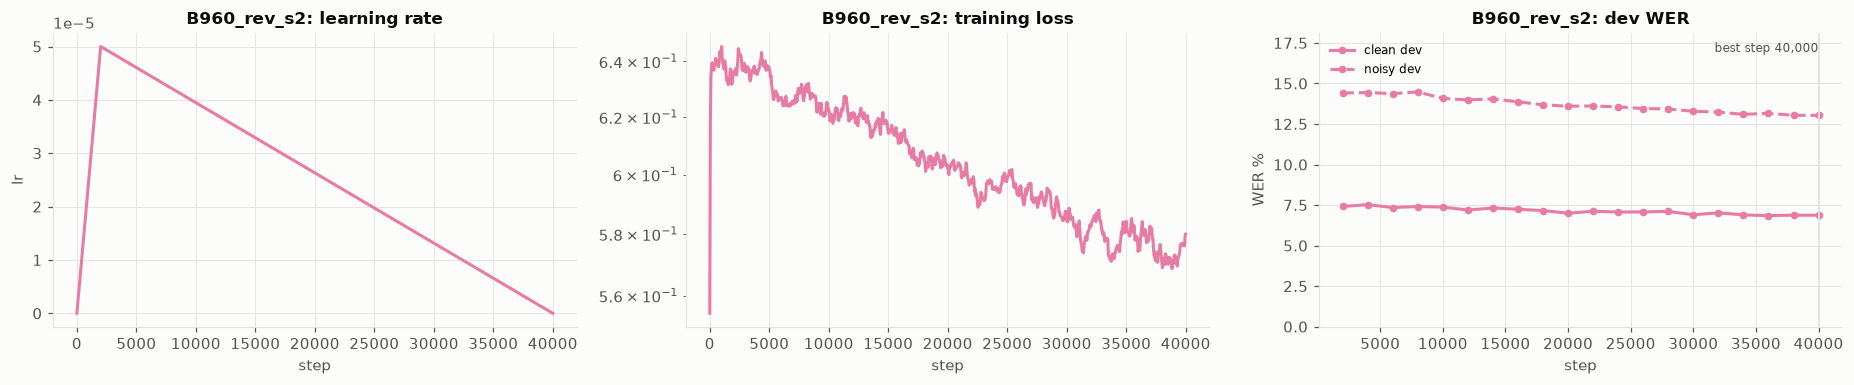

,best step,of steps,epochs,dev WER clean %,dev WER noisy %,dev WER mean %,dev CER clean %,final train loss,GPU hours
model,,,,,,,,,
B960_rev_s2,40000,40000,6,6.87,13.03,9.95,2.29,0.58,3.83


example at best step:
  REF HAT TOO CLOSE TO ME I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED 
  HYP HAT TOO CLOSE TO BE I COULDN'T GET IT EXPLAINED CHUNKY THE BOYS ROARED


In [11]:
show_run("B960_rev_s2")

### 4.7 Best checkpoints of all main models

,best step,of steps,epochs,dev WER clean %,dev WER noisy %,dev WER mean %,dev CER clean %,final train loss,GPU hours
model,,,,,,,,,
A_clean,34000,36000,59,9.29,34.87,22.08,3.25,0.226,3.82
B_noisy,34000,36000,59,9.26,17.37,13.32,3.23,0.421,3.83
B2_lr1e-4,36000,36000,59,9.08,17.03,13.06,3.23,0.387,3.95
B460,80000,80000,28,7.52,13.90,10.71,2.61,0.414,8.41
B960_rev,38000,40000,6,6.81,12.93,9.87,2.27,0.580,3.83
B960_rev_s2,40000,40000,6,6.87,13.03,9.95,2.29,0.580,3.83


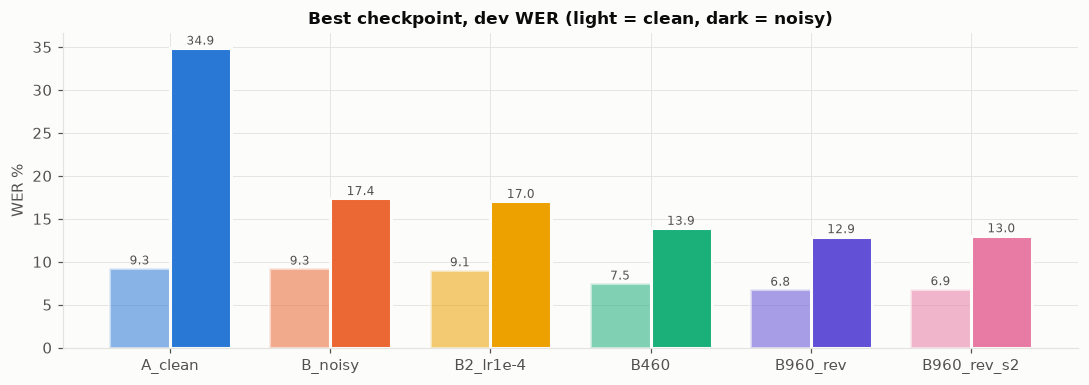

In [12]:
BEST = pd.DataFrame([best_row(n) for n in MAIN]).set_index("model")
display(BEST)
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(MAIN)); w = 0.38
ax.bar(x - w/2, BEST["dev WER clean %"], w, color=[COLOR[n] for n in MAIN], alpha=.55, label="clean dev", edgecolor=SURF, lw=2)
ax.bar(x + w/2, BEST["dev WER noisy %"], w, color=[COLOR[n] for n in MAIN], label="noisy dev", edgecolor=SURF, lw=2)
for i, n in enumerate(MAIN):
    ax.text(i - w/2, BEST.loc[n, "dev WER clean %"] + .4, f'{BEST.loc[n, "dev WER clean %"]:.1f}', ha="center", fontsize=8, color=INK2)
    ax.text(i + w/2, BEST.loc[n, "dev WER noisy %"] + .4, f'{BEST.loc[n, "dev WER noisy %"]:.1f}', ha="center", fontsize=8, color=INK2)
ax.set_xticks(x, MAIN); ax.set(title="Best checkpoint, dev WER (light = clean, dark = noisy)", ylabel="WER %")
plt.tight_layout(); plt.show()

## 5 · Hyperparameter sweep (7 short runs)
Each run uses the **Model B recipe** for 8,000 steps (about 13 epochs, 52 min) and changes **one** setting relative
to `hp_base`. All runs use the same seed and dev set; the test set was not used.

,change vs hp_base,epochs,dev WER clean %,dev WER noisy %,mean %,final train loss,Δ mean vs base
run,,,,,,,
hp_mask_light,"mask_time_prob 0.4 → 0.05, mask_feature_prob 0.1 → 0.0, ...",13,10.13,19.51,14.82,0.16,-2.31
hp_lr1e-4,lr 5e-05 → 0.0001,13,10.83,19.95,15.39,0.51,-1.74
hp_pclean0.5,p_clean 0.2 → 0.5,13,11.90,22.35,17.12,0.49,-0.01
hp_base,– (baseline),13,12.29,21.98,17.13,0.57,0.00
hp_snr-5,snr_min 0.0 → -5.0,13,12.75,22.01,17.38,0.67,0.25
hp_bs320,max_batch_seconds 640 → 320,6,13.69,23.70,18.70,0.61,1.56
hp_lr2e-5,lr 5e-05 → 2e-05,13,19.09,29.43,24.26,0.72,7.12


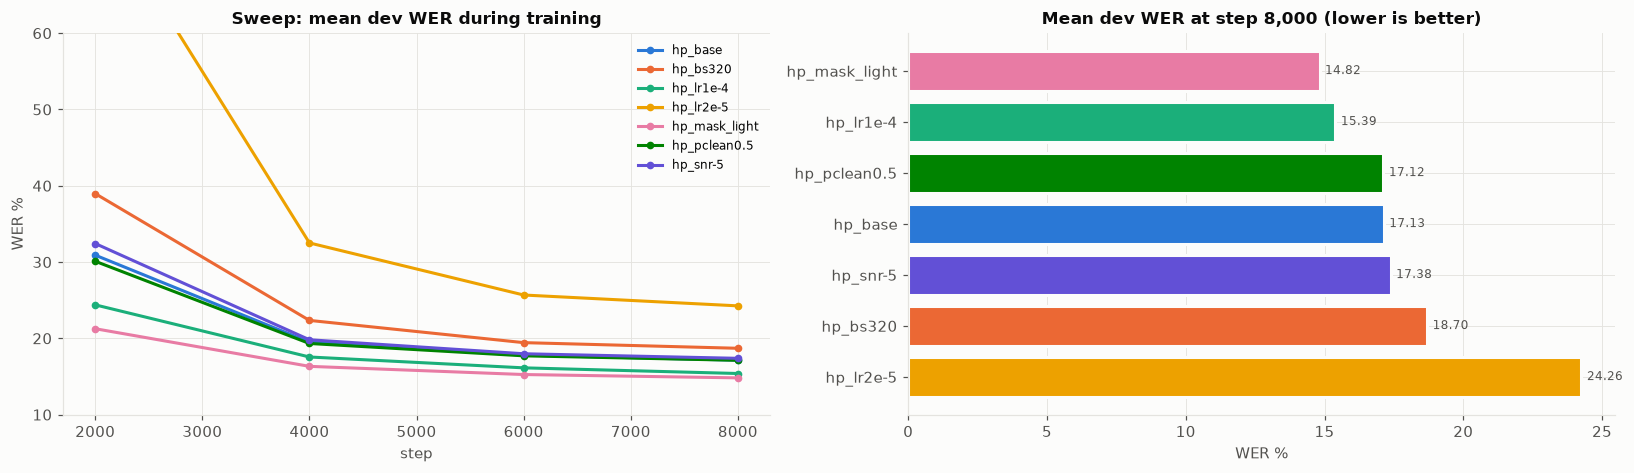

In [13]:
HP = sorted(p.name for p in RUNS.glob("hp_*"))
hcfg = {n: json.load(open(RUNS / n / "config.json")) for n in HP}
base = hcfg["hp_base"]
KEYS = ["lr", "max_batch_seconds", "p_clean", "snr_min", "mask_time_prob", "mask_feature_prob", "layerdrop"]
rows = []
for n in HP:
    e = pd.read_csv(RUNS / n / "eval_log.csv"); last = e.iloc[-1]; t = pd.read_csv(RUNS / n / "train_log.csv")
    change = ", ".join(f"{k} {base[k]} → {hcfg[n][k]}" for k in KEYS if hcfg[n].get(k) != base.get(k)) or "– (baseline)"
    rows.append({"run": n, "change vs hp_base": change, "epochs": int(t.epoch.max()),
                 "dev WER clean %": last.wer_clean * 100, "dev WER noisy %": last.wer_noisy * 100,
                 "mean %": last.wer_avg * 100, "final train loss": t.loss.tail(20).mean()})
SW = pd.DataFrame(rows).set_index("run")
SW["Δ mean vs base"] = SW["mean %"] - SW.loc["hp_base", "mean %"]
display(SW.sort_values("mean %").round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for i, n in enumerate(HP):
    e = pd.read_csv(RUNS / n / "eval_log.csv")
    axes[0].plot(e.step, e.wer_avg * 100, marker="o", ms=4, color=SERIES[i % 8], label=n)
axes[0].set(title="Sweep: mean dev WER during training", xlabel="step", ylabel="WER %", ylim=(10, 60)); axes[0].legend(fontsize=8)
s = SW.sort_values("mean %")
axes[1].barh(s.index, s["mean %"], color=[SERIES[HP.index(n) % 8] for n in s.index], edgecolor=SURF, lw=2)
for y, v in enumerate(s["mean %"]):
    axes[1].text(v + .2, y, f"{v:.2f}", va="center", fontsize=8, color=INK2)
axes[1].invert_yaxis(); axes[1].set(title="Mean dev WER at step 8,000 (lower is better)", xlabel="WER %")
plt.tight_layout(); plt.show()

- **Learning rate matters most.** 2e-5 is far too slow; 1e-4 is 1.7 points better than 5e-5 at 8k steps. At the full
  36k steps (B2 vs B, Section 4) the gap shrinks to about 0.3 points, so at 8k the sweep mainly measures speed.
- **Light masking** is best at 8k, but its training loss is 3.6× lower than the baseline's for only 2.3 points of dev
  gain, a sign of overfitting that would grow over a longer run. We kept strong masking.
- **Batch 320 s** sees half the audio per step and is worse; **p_clean 0.5** and **SNR down to −5 dB** make no real difference.

## 6 · Training stability and cost
All runs on one NVIDIA L40S (46 GB). The logged gradient norm is the norm **before** clipping to 1.0.

,steps,GPU hours,s / step,audio s / s,peak GPU mem GB,max logged grad norm,non-finite losses
run,,,,,,,
A_clean,36000,3.82,0.38,1583.54,10.85,13.71,0
B_noisy,36000,3.83,0.38,1581.08,10.85,14.55,0
B2_lr1e-4,36000,3.95,0.38,1580.10,10.85,14.37,0
B460,80000,8.41,0.37,1584.03,10.85,13.79,0
B960_rev,40000,3.83,0.34,1710.24,14.81,97.67,0
B960_rev_s2,40000,3.83,0.34,1710.68,14.81,28.34,0
hp_base,8000,0.85,0.38,1581.97,10.85,9.64,0
hp_bs320,8000,0.42,0.19,1646.65,10.26,19.94,0
hp_lr1e-4,8000,0.85,0.38,1581.72,10.85,12.46,0


**Total GPU time for all 13 runs: 33.2 h.** Non-finite losses in any run: 0.

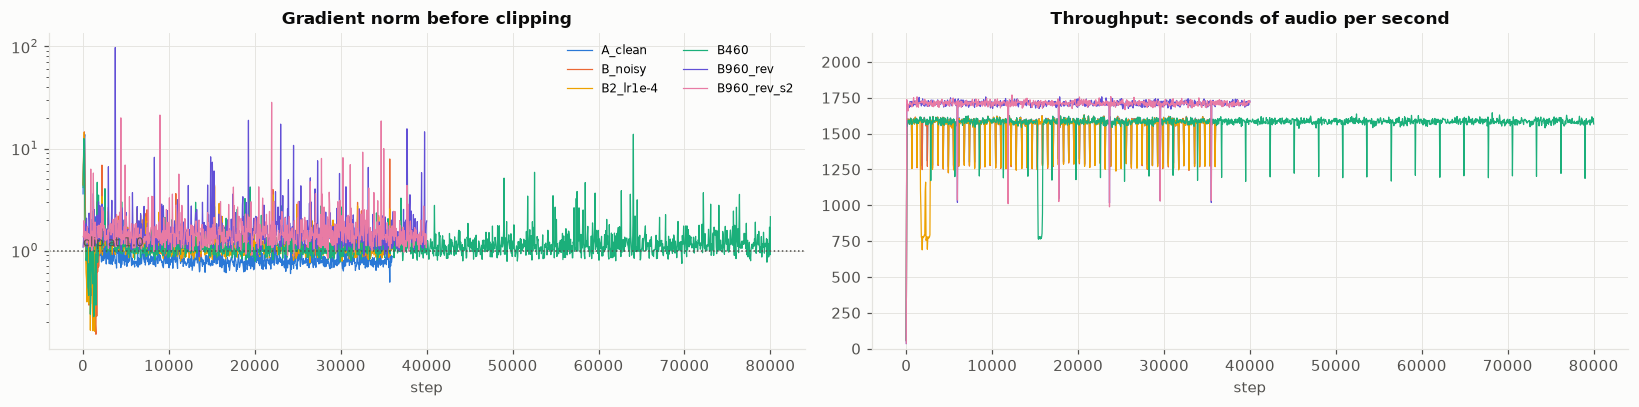

In [14]:
rows = []
for n in MAIN + HP:
    t = pd.read_csv(RUNS / n / "train_log.csv"); r = t.iloc[1:]
    rows.append({"run": n, "steps": int(t.step.max()), "GPU hours": (r.sec_per_step * t.step.diff().iloc[1:]).sum() / 3600,
                 "s / step": r.sec_per_step.median(), "audio s / s": r.audio_sec_per_sec.median(),
                 "peak GPU mem GB": t.max_mem_gb.max(), "max logged grad norm": t.grad_norm.max(),
                 "non-finite losses": int((~np.isfinite(t.loss)).sum())})
ST = pd.DataFrame(rows).set_index("run")
display(ST.round(2))
display(Markdown(f"**Total GPU time for all {len(ST)} runs: {ST['GPU hours'].sum():.1f} h.** "
                 f"Non-finite losses in any run: {ST['non-finite losses'].sum()}."))
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for n in MAIN:
    t = tl[n]
    axes[0].plot(t.step, t.grad_norm, color=COLOR[n], lw=.8, label=n)
    axes[1].plot(t.step, t.audio_sec_per_sec, color=COLOR[n], lw=.8, label=n)
axes[0].axhline(1.0, color=INK2, lw=1, ls=":"); axes[0].text(0, 1.1, "clip at 1.0", fontsize=8, color=INK2)
axes[0].set(title="Gradient norm before clipping", xlabel="step", yscale="log"); axes[0].legend(fontsize=8, ncol=2)
axes[1].set(title="Throughput: seconds of audio per second", xlabel="step", ylim=(0, 2200))
plt.tight_layout(); plt.show()

- No run had a non-finite loss. Gradient spikes happen (largest in B960_rev, where reverb and speed changes make some
  batches much harder), but clipping at 1.0 absorbs them and the loss curves show no jumps.
- Throughput is constant at about 1,550–1,750 s of audio per second, so a 36k-step run takes about 4 h.
- B960_rev uses more memory (14.8 GB) because speed 0.9× makes some utterances longer.

## 7 · Test results: greedy decoding (no language model)
Test grid: test-clean + test-other (5,559 utterances, speakers never seen in training) × 17 conditions
(clean; white, pink, brown and ESC-50 at 20/10/5/0 dB). **Brown noise and ESC-50 were never used in training.**
Greedy CTC decoding: this is the acoustic model alone.

In [15]:
G = ["ref_base960h"] + MAIN
def load_summary(path):
    s = pd.read_csv(path); s["snr_db"] = s.snr_db.astype(str); return s
greedy = pd.concat([load_summary(EVAL / m / "summary.csv") for m in G])

def pool(s):
    # word-weighted pooling of test-clean and test-other
    s = s[s.ls_split.isin(N_WORDS)].copy(); s["w"] = s.ls_split.map(N_WORDS)
    return (s.assign(e=s.wer * s.w).groupby(["model", "noise_type", "snr_db"])[["e", "w"]].sum()
              .pipe(lambda d: d.e / d.w).rename("wer").reset_index())

def headline(s, models):
    p, rows = pool(s), []
    for m in models:
        q, r = p[p.model == m], {"model": m}
        sm = s[s.model == m]
        r["test-clean"] = sm[(sm.ls_split == "test.clean") & (sm.noise_type == "clean")].wer.iloc[0] * 100
        r["test-other"] = sm[(sm.ls_split == "test.other") & (sm.noise_type == "clean")].wer.iloc[0] * 100
        for nt in ["esc50", "brown", "white", "pink"]:
            r[f"{nt} 0–5 dB"] = q[(q.noise_type == nt) & q.snr_db.isin(["0", "5"])].wer.mean() * 100
        r["all noisy, mean"] = q[q.noise_type != "clean"].wer.mean() * 100
        rows.append(r)
    return pd.DataFrame(rows).set_index("model")
GR = headline(greedy, G)
display(GR.round(2))

,test-clean,test-other,esc50 0–5 dB,brown 0–5 dB,white 0–5 dB,pink 0–5 dB,"all noisy, mean"
model,,,,,,,
ref_base960h,3.43,8.59,34.67,6.55,80.68,65.55,29.99
A_clean,5.85,13.03,38.29,10.26,71.53,56.05,29.86
B_noisy,6.19,13.08,20.12,10.02,29.09,23.20,16.07
B2_lr1e-4,5.89,13.11,19.56,9.99,28.56,22.81,15.85
B460,4.70,11.09,16.66,8.22,24.84,19.44,13.36
B960_rev,4.63,9.95,15.39,7.49,23.39,18.18,12.38
B960_rev_s2,4.64,10.07,15.52,7.57,23.50,18.27,12.47


Columns `… 0–5 dB` are the mean of the 0 dB and 5 dB conditions, pooled over test-clean and test-other.
**ESC-50 and brown are held-out noise types.** The reference model was trained on 960 h of *clean* speech only.

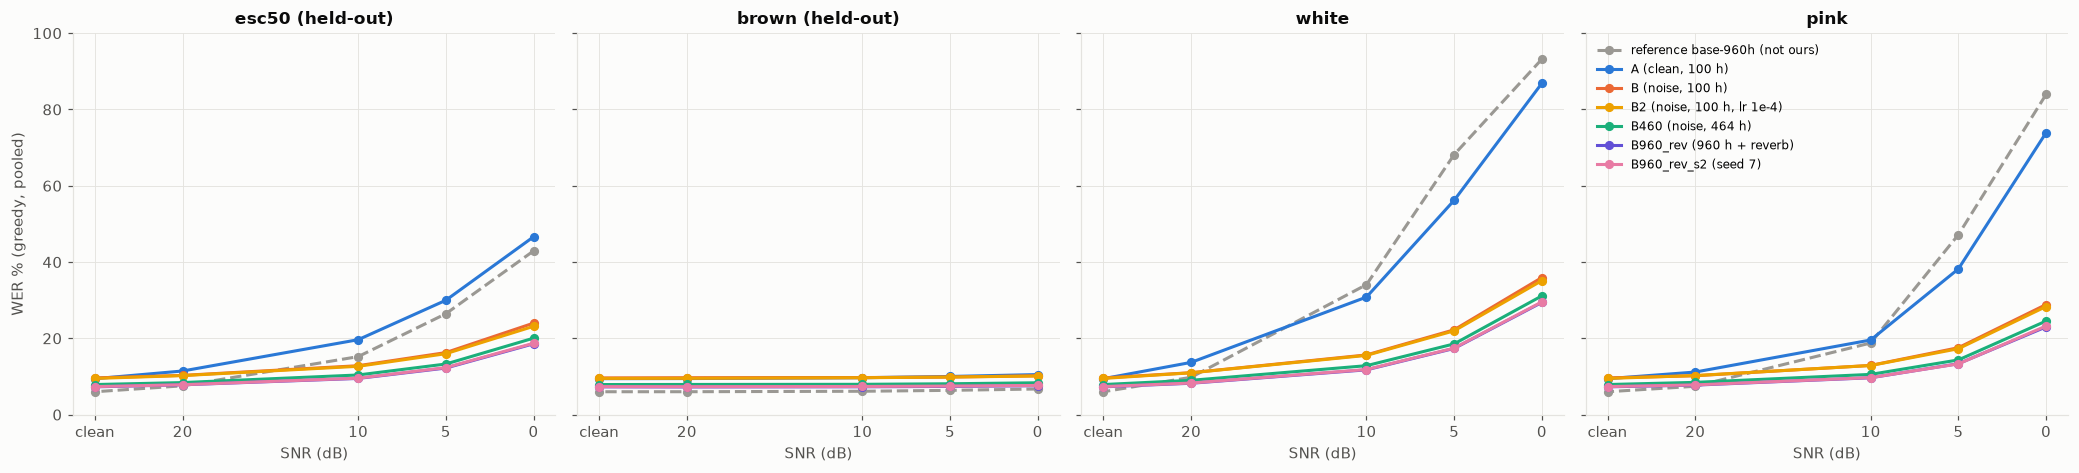

In [16]:
P = pool(greedy)
NOISES = ["esc50", "brown", "white", "pink"]
X = {"clean": 25, "20": 20, "10": 10, "5": 5, "0": 0}
fig, axes = plt.subplots(1, 4, figsize=(19, 4.4), sharey=True)
for ax, nt in zip(axes, NOISES):
    for m in G:
        q = P[(P.model == m) & (P.noise_type.isin([nt, "clean"]))].copy()
        q["x"] = q.snr_db.map(X); q = q.sort_values("x")
        ax.plot(q.x, q.wer * 100, marker="o", ms=5, color=COLOR[m], label=LABEL[m], ls="--" if m == "ref_base960h" else "-")
    ax.set_xticks(list(X.values()), ["clean", "20", "10", "5", "0"]); ax.invert_xaxis()
    ax.set(title=f"{nt}{' (held-out)' if nt in ('esc50', 'brown') else ''}", xlabel="SNR (dB)")
axes[0].set(ylabel="WER % (greedy, pooled)", ylim=(0, 100)); axes[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()

- Some lines overlap because the models are nearly identical: B and B2, and the two seeds B960_rev and B960_rev_s2.
- The **reference model (960 h clean)** is best on clean speech but collapses in white and pink noise: at 0 dB
  white noise it is worse than our clean-trained Model A.
- Every noise-trained model is far flatter. Each later model (B460, B960_rev) sits below the previous one at every
  SNR, including on the held-out ESC-50 noise.
- Brown noise has almost no effect on any model (about 97 % of its energy is below 300 Hz), so it does not
  separate the models.

## 8 · Test results: 4-gram LM and the final ROVER system
Beam search with the LibriSpeech 4-gram LM (α 0.8, β 2.0, beam 50; α/β tuned on dev). ROVER combines the
LM-decoded words of B960_rev_s2 (pivot), B960_rev and B460, with a vote weighted by word confidence (λ = 0.5).

In [17]:
L = ["A_clean", "B_noisy", "B2_lr1e-4", "B460", "B960_rev", "B960_rev_s2"]
lm = pd.concat([load_summary(EVAL / f"{m}_lm4" / "test_summary.csv").assign(model=m) for m in L] +
               [load_summary(EVAL / "rover3_final" / "test_summary.csv")])
LMR = headline(lm, L + ["rover3_final"])
display(LMR.round(2))
gain = (GR.loc[L, ["test-clean", "test-other", "esc50 0–5 dB"]] - LMR.loc[L, ["test-clean", "test-other", "esc50 0–5 dB"]])
display(Markdown("**WER points removed by the LM (greedy − LM):**")); display(gain.round(2))

,test-clean,test-other,esc50 0–5 dB,brown 0–5 dB,white 0–5 dB,pink 0–5 dB,"all noisy, mean"
model,,,,,,,
A_clean,3.69,9.04,32.58,6.94,66.15,50.18,25.22
B_noisy,3.70,8.85,15.09,6.55,22.79,17.63,11.62
B2_lr1e-4,3.67,9.18,14.82,6.70,22.57,17.44,11.61
B460,2.97,7.58,12.66,5.56,19.60,15.01,9.85
B960_rev,2.97,7.01,11.75,5.11,18.47,13.92,9.16
B960_rev_s2,2.97,7.06,11.81,5.13,18.62,14.07,9.22
rover3_final,2.89,6.92,11.42,5.03,17.97,13.63,8.94


**WER points removed by the LM (greedy − LM):**

,test-clean,test-other,esc50 0–5 dB
model,,,
A_clean,2.15,3.98,5.71
B_noisy,2.48,4.23,5.03
B2_lr1e-4,2.22,3.93,4.74
B460,1.73,3.52,4.00
B960_rev,1.66,2.94,3.64
B960_rev_s2,1.67,3.01,3.71


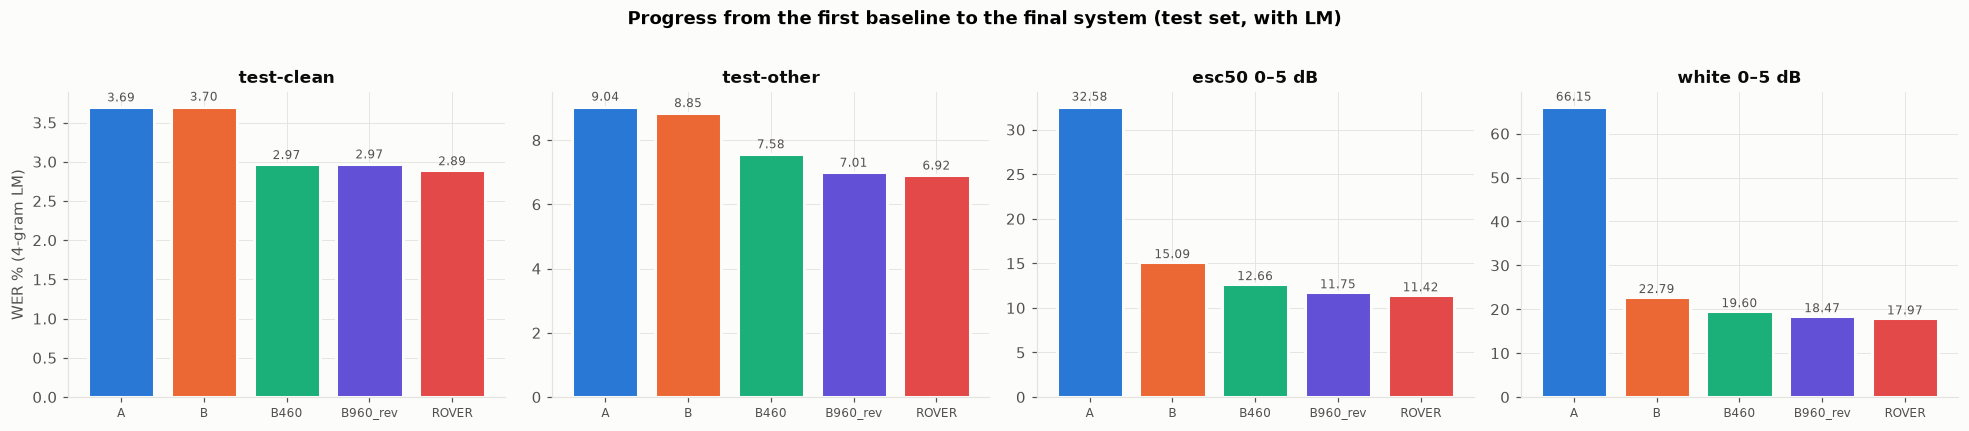

Final ROVER vs Model B: test-clean 3.70 → **2.89 %**, test-other 8.85 → **6.92 %**, held-out ESC-50 0–5 dB 15.09 → **11.42 %** (24 % relative).

In [18]:
order = ["A_clean", "B_noisy", "B460", "B960_rev", "rover3_final"]
cols = ["test-clean", "test-other", "esc50 0–5 dB", "white 0–5 dB"]
fig, axes = plt.subplots(1, len(cols), figsize=(18, 3.8))
for ax, c in zip(axes, cols):
    v = LMR.loc[order, c]
    ax.bar(range(len(order)), v, color=[COLOR[m] for m in order], edgecolor=SURF, lw=2)
    for i, y in enumerate(v):
        ax.text(i, y * 1.01, f"{y:.2f}", ha="center", va="bottom", fontsize=8, color=INK2)
    ax.set_xticks(range(len(order)), ["A", "B", "B460", "B960_rev", "ROVER"], fontsize=8)
    ax.set(title=c, ylabel="WER % (4-gram LM)" if c == cols[0] else None)
plt.suptitle("Progress from the first baseline to the final system (test set, with LM)", y=1.02, fontweight="bold")
plt.tight_layout(); plt.show()
best = LMR.loc["rover3_final"]; b = LMR.loc["B_noisy"]
display(Markdown(f"Final ROVER vs Model B: test-clean {b['test-clean']:.2f} → **{best['test-clean']:.2f} %**, "
                 f"test-other {b['test-other']:.2f} → **{best['test-other']:.2f} %**, held-out ESC-50 0–5 dB "
                 f"{b['esc50 0–5 dB']:.2f} → **{best['esc50 0–5 dB']:.2f} %** "
                 f"({100 * (1 - best['esc50 0–5 dB'] / b['esc50 0–5 dB']):.0f} % relative)."))

- The LM removes 2–4 points on clean speech and more in noise, for every model.
- With the LM, each step still helps: B → B460 (more data) is the largest gain; B460 → B960_rev helps most on
  test-other and in noise; ROVER adds a further 0.1–0.5 points in every condition.
- B2 (lr 1e-4) and B are within a few tenths of a point, and so are the two seeds B960_rev and B960_rev_s2.

## 9 · Harder held-out conditions (greedy decoding)
Real measured room impulse responses (rooms never used in training), reverberation combined with ESC-50, and
SNR −5 dB (below the training range). Files: `experiments/results/*_ext/summary.csv`.

model,A_clean,B_noisy,B2_lr1e-4,B460,B960_rev,B960_rev_s2
condition,,,,,,
"reverb, no noise",21.82,20.18,20.30,17.89,12.56,12.57
reverb+esc50 10 dB,41.37,29.93,29.82,26.72,20.01,20.04
reverb+esc50 5 dB,52.09,36.36,35.92,32.61,25.62,25.65
reverb+esc50 0 dB,65.97,47.51,46.73,43.01,35.70,35.75
esc50 -5 dB,61.65,38.21,36.85,32.91,31.01,31.28
pink -5 dB,98.11,55.32,53.86,49.57,47.28,47.25
white -5 dB,99.26,60.73,59.25,55.24,53.30,53.01


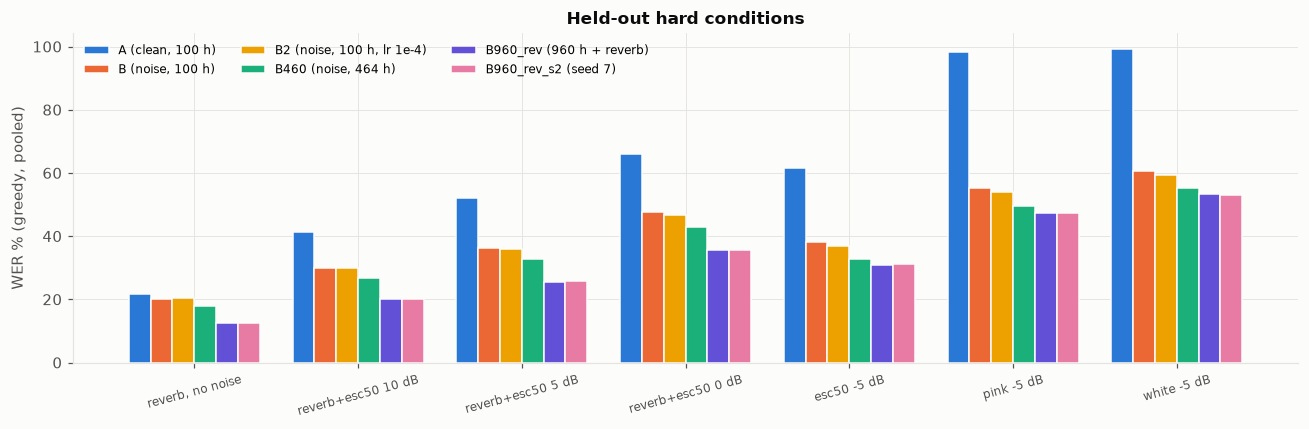

In [19]:
E = ["A_clean", "B_noisy", "B2_lr1e-4", "B460", "B960_rev", "B960_rev_s2"]
ext = pd.concat([load_summary(EVAL / f"{m}_ext" / "summary.csv").assign(model=m) for m in E if (EVAL / f"{m}_ext" / "summary.csv").exists()])
PX = pool(ext); PX["condition"] = PX.noise_type + " " + PX.snr_db.where(PX.snr_db != "clean", "").str.replace(r"^(-?\d+)$", r"\1 dB", regex=True)
TX = (PX.pivot_table(index="condition", columns="model", values="wer") * 100)[[m for m in E if m in PX.model.unique()]]
ORDER = ["reverb+clean ", "reverb+esc50 10 dB", "reverb+esc50 5 dB", "reverb+esc50 0 dB", "esc50 -5 dB", "pink -5 dB", "white -5 dB"]
TX = TX.loc[[c for c in ORDER if c in TX.index]].rename(index={"reverb+clean ": "reverb, no noise"})
display(TX.round(2))
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(TX)); w = .8 / TX.shape[1]
for i, m in enumerate(TX.columns):
    ax.bar(x + (i - TX.shape[1] / 2 + .5) * w, TX[m], w, color=COLOR[m], label=LABEL[m], edgecolor=SURF, lw=1)
ax.set_xticks(x, TX.index, rotation=15, fontsize=8); ax.set(ylabel="WER % (greedy, pooled)", title="Held-out hard conditions")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

Reverberation training (B960_rev) gives the largest relative gain anywhere in this project: real-room reverb without
noise falls from 20.2 % (B) to 12.6 % (−38 %). At −5 dB SNR, below anything seen in training, every model degrades
strongly; this is the main remaining limitation.

## 10 · Comparison with the published wav2vec 2.0 results
Baevski et al. (2020) report the same BASE model fine-tuned on 100 h and on 960 h of labelled LibriSpeech (clean
test sets only).

In [20]:
paper = pd.DataFrame([
    ["wav2vec 2.0 paper, BASE 100 h", "no LM", 6.1, 13.3], ["wav2vec 2.0 paper, BASE 100 h", "4-gram LM", 3.4, 8.0],
    ["wav2vec 2.0 paper, BASE 960 h", "no LM", 3.4, 8.5], ["wav2vec 2.0 paper, BASE 960 h", "4-gram LM", 2.6, 6.1]],
    columns=["system", "decoding", "test-clean", "test-other"])
ours = []
for m in ["A_clean", "B_noisy", "B460", "B960_rev"]:
    ours.append([f"ours: {LABEL[m]}", "no LM", GR.loc[m, "test-clean"], GR.loc[m, "test-other"]])
    ours.append([f"ours: {LABEL[m]}", "4-gram LM", LMR.loc[m, "test-clean"], LMR.loc[m, "test-other"]])
ours.append([f"ours: {LABEL['rover3_final']}", "4-gram LM", LMR.loc["rover3_final", "test-clean"], LMR.loc["rover3_final", "test-other"]])
display(pd.concat([paper, pd.DataFrame(ours, columns=paper.columns)]).set_index(["system", "decoding"]).round(2))

test-clean  test-other
system                          decoding                         
wav2vec 2.0 paper, BASE 100 h   no LM            6.10       13.30
                                4-gram LM        3.40        8.00
wav2vec 2.0 paper, BASE 960 h   no LM            3.40        8.50
                                4-gram LM        2.60        6.10
ours: A (clean, 100 h)          no LM            5.85       13.03
                                4-gram LM        3.69        9.04
ours: B (noise, 100 h)          no LM            6.19       13.08
                                4-gram LM        3.70        8.85
ours: B460 (noise, 464 h)       no LM            4.70       11.09
                                4-gram LM        2.97        7.58
ours: B960_rev (960 h + reverb) no LM            4.63        9.95
                                4-gram LM        2.97        7.01
ours: ROVER final (3 models)    4-gram LM        2.89        6.92

- Without an LM, our Model A (5.85 / 13.03) matches the paper's 100 h result (6.1 / 13.3): the training recipe and
  the evaluation pipeline are correct.
- Our models were trained mostly on **noisy** audio and are still on par with or better than the paper's clean-only
  results at the same amount of labelled data. With the LM, B960_rev and ROVER (2.89 / 6.92) are between the paper's
  100 h and 960 h results; the remaining gap is mostly the decoder (we use beam 50 and a small α/β grid).
- The paper reports clean speech only; all of our noisy results are outside the published benchmark.

## 11 · Summary
| Question | Answer from this notebook |
|---|---|
| Does noise training help on unseen noise? (O2) | Yes. Same data and recipe, ESC-50 0–5 dB greedy WER is about halved (A → B), at almost no cost on clean speech. |
| Which hyperparameter matters most? | Learning rate. 1e-4 learns faster than 5e-5, but at full length the gain is small (B2 vs B). |
| What gave the biggest improvement after B? | More labelled data (B460, 464 h), then 960 h with reverb/speed/telephone augmentation (B960_rev). |
| Is a single run reliable? | Two seeds of B960_rev differ by about 0.1 points; differences larger than that are real. |
| Best single model | **B960_rev**: 2.97 / 7.01 % test-clean / test-other, 11.75 % ESC-50 0–5 dB (with LM). Used in the app. |
| Best system | **ROVER of 3 models**: 2.89 / 6.92 %, 11.42 % ESC-50 0–5 dB, but 3× the compute. |
| Was training stable? | Yes: no non-finite losses in any of the 13 runs; gradient spikes absorbed by clipping. |
| Main limitation | Very low SNR (−5 dB) and reverberation + noise together remain hard (26–53 % WER). |